Is the average daily temprature between november 1-13th unusually warm this year compared to previous years?

# Dallas November Temperature Comparison

## Project question
Was November 1–10, 2026 warmer at DFW Airport than the same dates in 2021–2025?
# Dallas November Temperature Comparison

## Project question
Was November 1–10, 2026 warmer at DFW Airport than the same dates in 2021–2025?

## Data source
NOAA NCEI Daily Summaries, using DFW Airport station USW00003927.
Temperatures are in degrees Fahrenheit.

## Method
For each day, I calculated the midpoint of the daily high and low:
(TMAX + TMIN) / 2.

I averaged these daily midpoints for November 1–10 of each year.
I then compared the 2026 result with the average of the five yearly
results from 2021–2025.

## Data quality
For November 1–10 in each year from 2021–2026, checks found no missing
or duplicate dates, missing or nonnumeric temperatures, or daily highs
below daily lows.

## Findings
The 2026 average daily high–low midpoint was 66.15°F, compared with
a 2021–2025 baseline of 63.74°F—a difference of +2.41°F.
However, 2022 and 2024 were warmer than 2026.

## Limitations
This analysis covers ten days per year at one station.
The high–low midpoint is not an average of hourly temperatures.
This short comparison does not establish a long-term climate trend.

In [37]:
import urllib.request
import json
url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries"
    "&stations=USW00003927"
    "&startDate=2025-11-01"
    "&endDate=2025-11-13"
    "&dataTypes=TMAX,TMIN"
    "&units=standard"
    "&format=json"
)

print(url)

with urllib.request.urlopen(url) as response:
    data = json.loads(response.read())
    print(data)
    print(type(data))
    print(len(data))

    if len(data) > 0:
      print(data[0])



https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USW00003927&startDate=2025-11-01&endDate=2025-11-13&dataTypes=TMAX,TMIN&units=standard&format=json
[{'DATE': '2025-11-01', 'STATION': 'USW00003927', 'TMAX': '71', 'TMIN': '53'}, {'DATE': '2025-11-02', 'STATION': 'USW00003927', 'TMAX': '70', 'TMIN': '46'}, {'DATE': '2025-11-03', 'STATION': 'USW00003927', 'TMAX': '78', 'TMIN': '49'}, {'DATE': '2025-11-04', 'STATION': 'USW00003927', 'TMAX': '77', 'TMIN': '53'}, {'DATE': '2025-11-05', 'STATION': 'USW00003927', 'TMAX': '81', 'TMIN': '58'}, {'DATE': '2025-11-06', 'STATION': 'USW00003927', 'TMAX': '84', 'TMIN': '59'}, {'DATE': '2025-11-07', 'STATION': 'USW00003927', 'TMAX': '81', 'TMIN': '59'}, {'DATE': '2025-11-08', 'STATION': 'USW00003927', 'TMAX': '82', 'TMIN': '52'}, {'DATE': '2025-11-09', 'STATION': 'USW00003927', 'TMAX': '61', 'TMIN': '42'}, {'DATE': '2025-11-10', 'STATION': 'USW00003927', 'TMAX': '56', 'TMIN': '35'}, {'DATE': '2025-11-11', 'STATION': 'US

In [38]:
for record in data:
  date = record["DATE"]
  high = float(record["TMAX"])
  low = float(record["TMIN"])
  midpoint = (high + low) / 2
  print(date, midpoint)


2025-11-01 62.0
2025-11-02 58.0
2025-11-03 63.5
2025-11-04 65.0
2025-11-05 69.5
2025-11-06 71.5
2025-11-07 70.0
2025-11-08 67.0
2025-11-09 51.5
2025-11-10 45.5
2025-11-11 56.5
2025-11-12 61.5
2025-11-13 69.0


In [39]:
total = 0
count = 0

for record in data:
    high = float(record["TMAX"])
    low = float(record["TMIN"])
    midpoint = (high + low) / 2
    total = midpoint + total
    count = count + 1
if count > 0:
    period_average = total / count
    print("Period average:", period_average)
    print(len(data))



Period average: 62.34615384615385
13


In [40]:
for record in data:
    print(
        record["DATE"],
        record.get("TMAX"),
        record.get("TMIN")
    )

print("Records returned:", len(data))
print("Period average:", period_average)

2025-11-01 71 53
2025-11-02 70 46
2025-11-03 78 49
2025-11-04 77 53
2025-11-05 81 58
2025-11-06 84 59
2025-11-07 81 59
2025-11-08 82 52
2025-11-09 61 42
2025-11-10 56 35
2025-11-11 72 41
2025-11-12 77 46
2025-11-13 82 56
Records returned: 13
Period average: 62.34615384615385


In [41]:
def get_november_data(year):
    url = (
        "https://www.ncei.noaa.gov/access/services/data/v1"
        "?dataset=daily-summaries"
        "&stations=USW00003927"
        f"&startDate={year}-11-01"
        f"&endDate={year}-11-13"
        "&dataTypes=TMAX,TMIN"
        "&units=standard"
        "&format=json"
    )

    with urllib.request.urlopen(url) as response:
        records = json.loads(response.read())

    return records

In [42]:
for year in range(2021, 2027):
    records = get_november_data(year)
    date_count = {}
    issues = 0

    for record in records:
        date = record["DATE"]

        # Only check the dates used in our comparison
        if f"{year}-11-01" <= date <= f"{year}-11-10":
            date_count[date] = date_count.get(date, 0) + 1

            try:
                high = float(record["TMAX"])
                low = float(record["TMIN"])
            except (KeyError, TypeError, ValueError):
                print(year, "Missing or invalid temperature:", date)
                issues = issues + 1
            else:
                if high < low:
                    print(year, "High below low:", date)
                    issues = issues + 1

    for date, count in date_count.items():
        if count > 1:
            print(year, "Duplicate date:", date)
            issues = issues + 1

    for day in range(1, 11):
        expected_date = f"{year}-11-{day:02d}"

        if expected_date not in date_count:
            print(year, "Missing date:", expected_date)
            issues = issues + 1

    print(year, "— Issues found:", issues)

2021 — Issues found: 0
2022 — Issues found: 0
2023 — Issues found: 0
2024 — Issues found: 0
2025 — Issues found: 0
2026 — Issues found: 0


In [43]:
def calculate_period_average(records):
    total = 0
    count = 0

    for record in records:
        high = float(record["TMAX"])
        low = float(record["TMIN"])
        midpoint = (high + low) / 2

        total = total + midpoint
        count = count + 1

    if count > 0:
        return total / count

    return None
print(calculate_period_average(data))



62.34615384615385


In [44]:
for year in range(2021, 2026):
    records = get_november_data(year)
    period_average = calculate_period_average(records)
    print(year, len(records), period_average)

2021 13 57.5
2022 13 63.34615384615385
2023 13 61.84615384615385
2024 13 66.61538461538461
2025 13 62.34615384615385


In [45]:
yearly_averages = {}

for year in range(2021, 2026):
    records = get_november_data(year)
    period_average = calculate_period_average(records)

    yearly_averages[year] = period_average

print(yearly_averages)

{2021: 57.5, 2022: 63.34615384615385, 2023: 61.84615384615385, 2024: 66.61538461538461, 2025: 62.34615384615385}


In [46]:
records_2026 = get_november_data(2026)
average_2026 = calculate_period_average(records_2026)

print("Records:", len(records_2026))
print("2026 average:", average_2026)

Records: 13
2026 average: 65.57692307692308


In [47]:
for record in records_2026:
    print(
        record["DATE"],
        record.get("TMAX"),
        record.get("TMIN")
    )

2026-11-01 79 60
2026-11-02 85 65
2026-11-03 77 60
2026-11-04 76 52
2026-11-05 82 52
2026-11-06 73 53
2026-11-07 69 50
2026-11-08 70 56
2026-11-09 72 55
2026-11-10 78 59
2026-11-11 80 56
2026-11-12 79 51
2026-11-13 68 48


In [48]:
matching_records = []

for record in records:
    day = int(record["DATE"][-2:])

    if day <= 10:
        matching_records.append(record)

In [49]:
matched_averages = {}

for year in range(2021, 2026):
    records = get_november_data(year)

    matching_records = []

    for record in records:
        day = int(record["DATE"][-2:])

        if day <= 10:
            matching_records.append(record)

    period_average = calculate_period_average(matching_records)
    matched_averages[year] = period_average

    print(year, len(matching_records), period_average)

2021 10 58.25
2022 10 68.15
2023 10 62.85
2024 10 67.1
2025 10 62.35


In [50]:
total = 0

for average in matched_averages.values():
    total = total + average

baseline_average = total / len(matched_averages)
difference = average_2026 - baseline_average

print(f"2021–2025 baseline: {baseline_average:.2f}°F")
print(f"2026 difference: {difference:+.2f}°F")

2021–2025 baseline: 63.74°F
2026 difference: +1.84°F


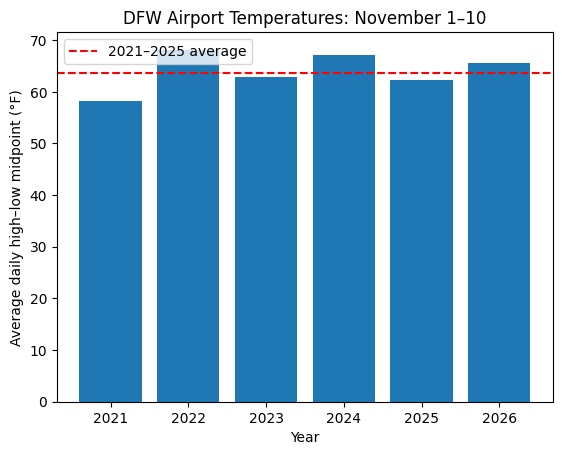

In [51]:
import matplotlib.pyplot as plt

years = list(matched_averages.keys())
averages = list(matched_averages.values())

years.append(2026)
averages.append(average_2026)

plt.bar(years, averages)
plt.axhline(
    baseline_average,
    color="red",
    linestyle="--",
    label="2021–2025 average"
)

plt.title("DFW Airport Temperatures: November 1–10")
plt.xlabel("Year")
plt.ylabel("Average daily high–low midpoint (°F)")
plt.xticks(years)
plt.legend()
plt.show()

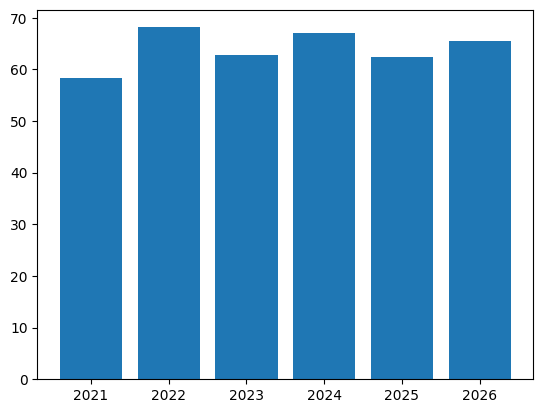

In [52]:
import matplotlib.pyplot as plt

years = list(matched_averages.keys())
averages = list(matched_averages.values())

years.append(2026)
averages.append(average_2026)

plt.bar(years, averages)
plt.show()

For November 1–10, the average daily high–low midpoint at DFW Airport was 66.15°F in 2026, which was 2.41°F above the 2021–2025 average. However, 2022 and 2024 were warmer. This short comparison alone does not establish a long-term climate trend.

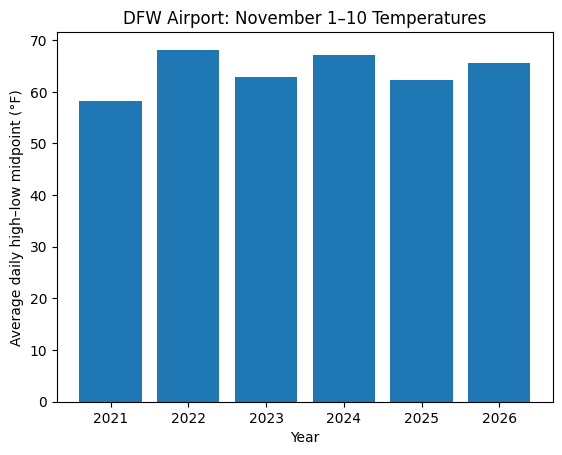

In [53]:
plt.bar(years, averages)
plt.title("DFW Airport: November 1–10 Temperatures")
plt.xlabel("Year")
plt.ylabel("Average daily high–low midpoint (°F)")
plt.xticks(years)
plt.show()

In [54]:
with open("dallas_results.csv", "w") as output:
    output.write("year,average_temperature\n")
    for year, average in matched_averages.items():
        output.write(f"{year},{average:.2f}\n")

    output.write(f"2026,{average_2026:.2f}\n")

Now we check for duplicates

In [55]:
date_count = {}

for record in records_2026:
    date = record["DATE"]
    date_count[date] = date_count.get(date, 0) + 1

for date, count in date_count.items():
    if count > 1:
        print("Duplicate date:", date, "Records:", count)

In [56]:
for day in range(1, 11):
    expected_date = f"2026-11-{day:02d}"

    if expected_date not in date_count:
        print("Missing date:", expected_date)

In [57]:
issues = 0

for record in records_2026:
    date = record["DATE"]

    try:
        high = float(record["TMAX"])
        low = float(record["TMIN"])
    except (KeyError, TypeError, ValueError):
        print("Missing or invalid temperature:", date)
        issues = issues + 1
    else:
        if high < low:
            print("High is below low:", date)
            issues = issues + 1

print("Temperature issues found:", issues)

Temperature issues found: 0
